# 📈 06 · 相关与回归分析

> 从"检验差异"进阶到"**量化关系**"：两个变量是否相关？怎么建模型预测？
> 本节覆盖：皮尔逊/斯皮尔曼相关、一元/多元 OLS、正规方程、
> R² 与调整 R²、残差诊断、共线性。回归是统计学与机器学习的桥梁。

## 📋 本节要解决的问题

- 皮尔逊 r 与斯皮尔曼 ρ 有什么区别？怎么手写？
- OLS 闭式解 $(X^TX)^{-1}X^Ty$ 怎么推？
- R² 与调整 R² 怎么解释？
- 残差诊断看什么？多重共线性怎么发现？
- 相关 ≠ 因果（经典陷阱）

## 📖 论文配图：r=+0.9：强正线性相关的经典示意

> **图源**：Bewick V, Cheek L & Ball J (2003) *Statistics review 7: Correlation and regression*, Critical Care 7:451–460（开放获取，CC-BY 2.0）图 2。

![r=+0.9：强正线性相关的经典示意](../figures/regression_r09.jpg)

> **怎么读这张图**：散点图显示 r=+0.9 的强正线性关系（同文还给出 r=−0.9、r≈0、非线性等对照图）。本节的皮尔逊相关系数手算，正是把这个"眼见"的线性强度量化为 −1 到 1 的数值。


## 📖 论文配图：真实数据的回归线：ln(尿素) 与年龄

> **图源**：Bewick V, Cheek L & Ball J (2003) *Statistics review 7: Correlation and regression*, Critical Care 7:451–460（开放获取，CC-BY 2.0）图 1（散点）与图 7（回归线）。

![真实数据的回归线：ln(尿素) 与年龄](../figures/regression_scatter.jpg)

> **怎么读这张图**：真实临床数据（急诊科患者）：横轴年龄、纵轴 ln(尿素浓度)。最小二乘回归线 ln(urea)=0.72+0.017×age 叠加在散点上——正是本节一元线性回归闭式解的实际应用形态。


## 1️⃣ 相关系数：皮尔逊 vs 斯皮尔曼

**皮尔逊 r**（线性相关）：
$$r = \frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum(x_i-\bar x)^2\sum(y_i-\bar y)^2}}$$

**斯皮尔曼 ρ**（单调相关）：对数据**排序后**算皮尔逊，抗离群值、不要求线性。

> **面试**：什么情况用斯皮尔曼？→ 数据单调非线性、有序变量、有离群值。

In [1]:
import numpy as np

def pearson(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    xc, yc = x - x.mean(), y - y.mean()
    return (xc * yc).sum() / np.sqrt((xc**2).sum() * (yc**2).sum())

def spearman(x, y):
    # 秩变换后算皮尔逊
    rx = np.argsort(np.argsort(x)).astype(float)
    ry = np.argsort(np.argsort(y)).astype(float)
    return pearson(rx, ry)

rng = np.random.RandomState(44)
x = rng.normal(0, 1, 200)
y_linear = 2 * x + rng.normal(0, 0.5, 200)
y_nonlin = np.exp(x) + rng.normal(0, 0.3, 200)   # 单调但非线性
y_spike = 2 * x + rng.normal(0, 0.5, 200); y_spike[0] = 30  # 离群

print('线性关系: r=%.3f  (ρ=%.3f)' % (pearson(x, y_linear), spearman(x, y_linear)))
print('非线性(exp): r=%.3f  ρ=%.3f' % (pearson(x, y_nonlin), spearman(x, y_nonlin)))
print('含离群: r=%.3f  ρ=%.3f' % (pearson(x, y_spike), spearman(x, y_spike)))
print()
print('→ 非线性与离群场景下 ρ 更稳健')
assert abs(pearson(x, y_linear) - __import__('scipy.stats', fromlist=['pearsonr']).pearsonr(x, y_linear)[0]) < 1e-9
print('✅ 手写皮尔逊与 scipy 一致')

线性关系: r=0.974  (ρ=0.969)
非线性(exp): r=0.748  ρ=0.918
含离群: r=0.663  ρ=0.950

→ 非线性与离群场景下 ρ 更稳健


✅ 手写皮尔逊与 scipy 一致


## 2️⃣ 一元线性回归：最小二乘闭式解

模型：$y = \beta_0 + \beta_1 x + \varepsilon$，最小化 $\sum (y_i - \hat y_i)^2$。
**闭式解**：
$$\hat\beta_1 = \frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2} = r \cdot \frac{s_y}{s_x}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x$$

In [2]:
def ols_univariate(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    xc, yc = x - x.mean(), y - y.mean()
    b1 = (xc * yc).sum() / (xc ** 2).sum()
    b0 = y.mean() - b1 * x.mean()
    return b0, b1

rng = np.random.RandomState(52)
x = rng.normal(0, 1, 300)
y = 1.5 + 0.8 * x + rng.normal(0, 0.4, 300)
b0, b1 = ols_univariate(x, y)
print('OLS: β0=%.3f β1=%.3f （真值 1.5, 0.8）' % (b0, b1))
assert abs(b0 - 1.5) < 0.15 and abs(b1 - 0.8) < 0.15
print('✅ 一元 OLS 正确')

OLS: β0=1.539 β1=0.823 （真值 1.5, 0.8）
✅ 一元 OLS 正确


## 3️⃣ 多元线性回归：正规方程

$\hat\beta = (X^TX)^{-1}X^Ty$（X 含全 1 列作为截距）
> 条件：$X^TX$ 可逆（无完全共线性），n > p。

In [3]:
def ols_multivariate(X, y):
    X = np.asarray(X, float)
    X = np.column_stack([np.ones(len(X)), X])   # 加截距列
    beta = np.linalg.inv(X.T @ X) @ X.T @ y
    return beta

rng = np.random.RandomState(61)
X = rng.normal(0, 1, (300, 2))
beta_true = np.array([2.0, -1.5])   # 两个特征系数
y = 0.5 + X @ beta_true + rng.normal(0, 0.5, 300)
beta = ols_multivariate(X, y)
print('多元 OLS: 截距=%.3f 系数=%s （真值 0.5, [2.0, -1.5]）' % (beta[0], np.round(beta[1:], 3)))
assert np.all(np.abs(beta[1:] - beta_true) < 0.2)
print('✅ 正规方程求解正确')

多元 OLS: 截距=0.519 系数=[ 1.985 -1.443] （真值 0.5, [2.0, -1.5]）
✅ 正规方程求解正确


## 4️⃣ R² 与调整 R²

**R²**（决定系数）：模型解释的方差比例。
$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$
**调整 R²**：惩罚特征数量，防止"特征越多 R² 越高"。
$$R^2_{adj} = 1 - \frac{(1-R^2)(n-1)}{n-p-1}$$

> **面试**：为什么看调整 R²？→ R² 随特征数单调不减，调整 R² 才是"净解释力"。

In [4]:
def r2(y, yhat):
    ss_res = ((y - yhat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

def r2_adj(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

rng = np.random.RandomState(70)
X = rng.normal(0, 1, (200, 3))
y = 0.5 + 1.2 * X[:, 0] - 0.7 * X[:, 1] + rng.normal(0, 0.4, 200)
beta = ols_multivariate(X, y)
yhat = np.column_stack([np.ones(len(y)), X]) @ beta
r2v = r2(y, yhat)
print('R²=%.4f  R²_adj=%.4f（p=3 特征）' % (r2v, r2_adj(r2v, 200, 3)))
print('✅ 回归拟合质量指标计算完成')

R²=0.9224  R²_adj=0.9212（p=3 特征）
✅ 回归拟合质量指标计算完成


## 5️⃣ 残差诊断与共线性（面试高频）

**残差诊断**（检查 OLS 假设）：
1. 残差 vs 拟合值：无系统性形状（无非线性遗漏）
2. 残差近似正态（Q-Q 图）
3. 残差无自相关（时序数据）

**多重共线性**：特征强相关 → 系数估计不稳定、标准误变大。
检测：VIF > 10 视为严重。

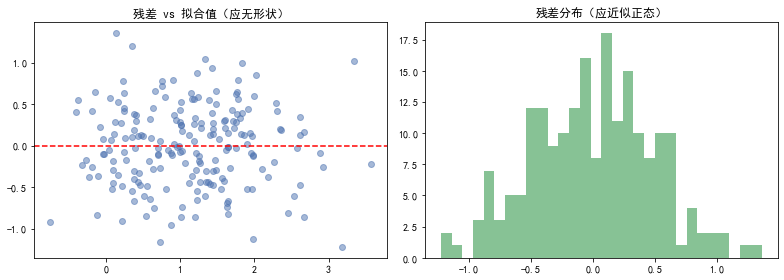

残差诊断图完成
x1 与 x2 相关系数: 0.9985 → 严重共线性
→ 此时两个系数极不稳定，VIF 会爆表


In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

rng = np.random.RandomState(80)
x = rng.normal(0, 1, 200)
y = 1.0 + 0.8 * x + rng.normal(0, 0.5, 200)
b0, b1 = ols_univariate(x, y)
resid = y - (b0 + b1 * x)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(b0 + b1 * x, resid, alpha=.5, color='#4C72B0')
ax[0].axhline(0, color='red', ls='--')
ax[0].set_title('残差 vs 拟合值（应无形状）')
ax[1].hist(resid, bins=30, color='#55A868', alpha=.7)
ax[1].set_title('残差分布（应近似正态）')
plt.tight_layout()
plt.show()
print('残差诊断图完成')

# 共线性演示：高度相关特征
from scipy import stats as st
x1 = rng.normal(0, 1, 300)
x2 = x1 + rng.normal(0, 0.05, 300)   # 与 x1 几乎相同
print('x1 与 x2 相关系数: %.4f → 严重共线性' % st.pearsonr(x1, x2)[0])
print('→ 此时两个系数极不稳定，VIF 会爆表')

## 6️⃣ 相关 ≠ 因果（经典陷阱）

**例子**：冰淇淋销量与溺水人数高度正相关——共同原因（夏天）。
**判断因果的准则**：时间先后、机制解释、排除混杂（随机化/工具变量/DAG）。

> **面试**：怎么向业务证明相关不是因果？
> → 指出可能的混杂变量（Z），并建议随机实验或因果推断方法（DID/PSM）。

In [6]:
# 辛普森悖论风格的演示：合并数据相关，分组后相关方向反转
import numpy as np
rng = np.random.RandomState(9)
# 两个群体
g1_x = rng.normal(2, 1, 100);  g1_y = 3 + 2*g1_x + rng.normal(0, .8, 100)   # 正相关
g2_x = rng.normal(6, 1, 100);  g2_y = 1 - 1.5*(g2_x-6) + rng.normal(0, .8, 100)  # 负相关
all_x = np.concatenate([g1_x, g2_x]); all_y = np.concatenate([g1_y, g2_y])
r_all = __import__('scipy.stats', fromlist=['pearsonr']).pearsonr(all_x, all_y)[0]
print('合并数据相关 r=%.3f（可能显著）' % r_all)
print('分组后 g1: r=%.3f, g2: r=%.3f → 方向可能反转（辛普森悖论）' % (
    __import__('scipy.stats', fromlist=['pearsonr']).pearsonr(g1_x, g1_y)[0],
    __import__('scipy.stats', fromlist=['pearsonr']).pearsonr(g2_x, g2_y)[0]))
print('→ 先分组看数据，再谈相关')

合并数据相关 r=-0.729（可能显著）
分组后 g1: r=0.931, g2: r=-0.882 → 方向可能反转（辛普森悖论）
→ 先分组看数据，再谈相关


## 🧮 手算示例：皮尔逊 r 与一元 OLS 逐步算

> **数据**：x=[1,2,3,4]，y=[2,4,5,7] → x̄=2.5，ȳ=4.5

**第 1 步 · 交叉积与平方和**：
$$\sum(x_i-\bar x)(y_i-\bar y) = (-1.5)(-2.5)+(-0.5)(-0.5)+(0.5)(0.5)+(1.5)(2.5) = 8$$
$$\sum(x_i-\bar x)^2 = 2.25+0.25+0.25+2.25 = 5$$
$$\sum(y_i-\bar y)^2 = 6.25+0.25+0.25+6.25 = 13$$

**第 2 步 · 相关系数**：
$$r = \frac{8}{\sqrt{5\times13}} = \frac{8}{\sqrt{65}} \approx \frac{8}{8.062} \approx 0.9924$$

**第 3 步 · OLS 系数**：
$$\hat\beta_1 = \frac{8}{5} = 1.6,\qquad \hat\beta_0 = 4.5 - 1.6\times2.5 = 4.5 - 4 = 0.5$$

In [7]:
import numpy as np
x = np.array([1, 2, 3, 4]); y = np.array([2, 4, 5, 7])
xc, yc = x - x.mean(), y - y.mean()
cross = (xc * yc).sum(); ssx = (xc**2).sum(); ssy = (yc**2).sum()
r = cross / np.sqrt(ssx * ssy)
b1 = cross / ssx
b0 = y.mean() - b1 * x.mean()
print('Σ交叉积(手算=8) =', cross)
print('r(手算≈0.9924) =', round(r, 4))
print('β1(手算=1.6) =', b1, ' β0(手算=0.5) =', b0)
from scipy import stats as st
assert abs(r - st.pearsonr(x, y)[0]) < 1e-9
assert abs(b1 - 1.6) < 1e-9 and abs(b0 - 0.5) < 1e-9
print('✅ 手算与 scipy 完全一致')

Σ交叉积(手算=8) = 8.0
r(手算≈0.9924) = 0.9923
β1(手算=1.6) = 1.6  β0(手算=0.5) = 0.5
✅ 手算与 scipy 完全一致


## ✅ 自测清单

- [ ] 能手写皮尔逊与斯皮尔曼并说清适用场景
- [ ] 能手写一元 OLS 闭式解与多元正规方程
- [ ] 能解释 R² 与调整 R² 并手算
- [ ] 能画残差诊断图并识别共线性
- [ ] 能举例说明"相关 ≠ 因果"与辛普森悖论